In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()

while ROOT.name != "porto-santos":
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Raiz do projeto não encontrada.")
    ROOT = ROOT.parent

BASE = ROOT / "data" / "processed" / "precipitacao_historica"

df = pd.read_csv(
    BASE / "precipitacao_mensal_limpa.csv",
    parse_dates=["data_mes"]
)

display(df.head())

,data_mes,ano,mes,nome_mes,precipitacao_mensal,referencia_30_anos,anomalia_absoluta,anomalia_percentual
0,1996-01-01,1996,1,JANEIRO,208.8,340.5,-131.7,-38.68
1,1996-02-01,1996,2,FEVEREIRO,552.6,292.6,260.0,88.86
2,1996-03-01,1996,3,MARÇO,770.5,262.1,508.4,193.97
3,1996-04-01,1996,4,ABRIL,540.4,211.7,328.7,155.27
4,1996-05-01,1996,5,MAIO,167.9,161.9,6.0,3.71


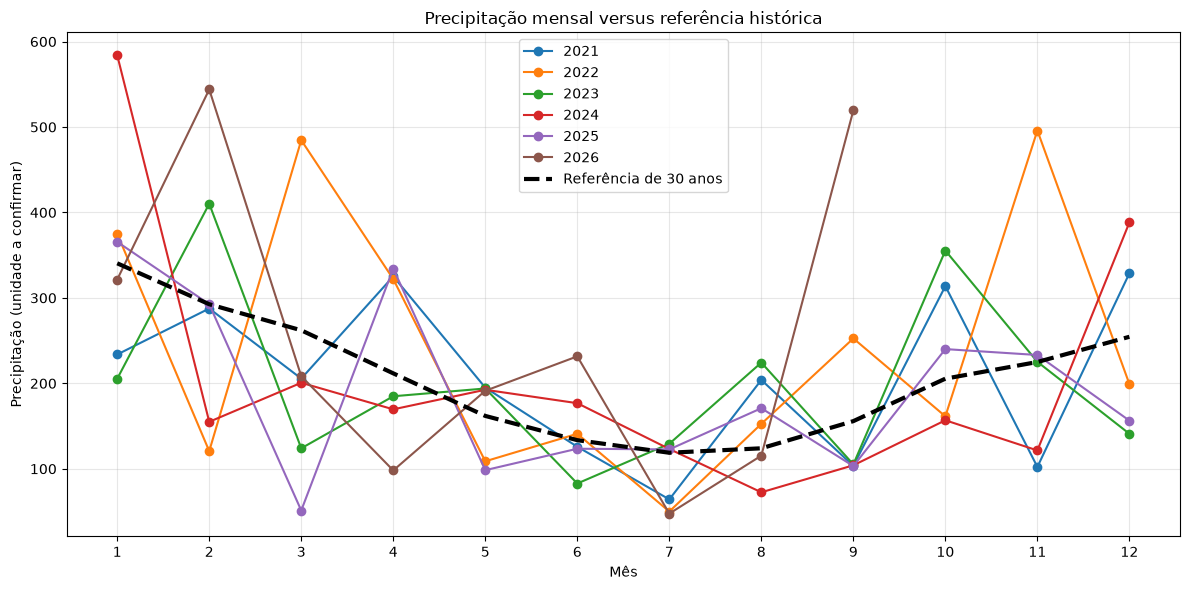

In [2]:
# Analisar somente o período do projeto
periodo = df[df["ano"].between(2021, 2026)].copy()

referencia = (
    periodo[["mes", "referencia_30_anos"]]
    .drop_duplicates("mes")
    .sort_values("mes")
)

plt.figure(figsize=(12, 6))

for ano, grupo in periodo.groupby("ano"):
    plt.plot(
        grupo["mes"],
        grupo["precipitacao_mensal"],
        marker="o",
        label=str(ano)
    )

plt.plot(
    referencia["mes"],
    referencia["referencia_30_anos"],
    color="black",
    linewidth=3,
    linestyle="--",
    label="Referência de 30 anos"
)

plt.title("Precipitação mensal versus referência histórica")
plt.xlabel("Mês")
plt.ylabel("Precipitação (unidade a confirmar)")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [3]:
maiores_desvios = (
    periodo.dropna(subset=["anomalia_absoluta"])
    .sort_values("anomalia_absoluta", ascending=False)
    [
        [
            "ano",
            "mes",
            "nome_mes",
            "precipitacao_mensal",
            "referencia_30_anos",
            "anomalia_absoluta",
            "anomalia_percentual"
        ]
    ]
    .head(15)
)

display(maiores_desvios)

,ano,mes,nome_mes,precipitacao_mensal,referencia_30_anos,anomalia_absoluta,anomalia_percentual
368,2026,9,SETEMBRO,519.4,155.8,363.6,233.38
322,2022,11,NOVEMBRO,495.9,225.0,270.9,120.40
361,2026,2,FEVEREIRO,544.0,292.6,251.4,85.92
336,2024,1,JANEIRO,584.0,340.5,243.5,71.51
314,2022,3,MARÇO,484.6,262.1,222.5,84.89
333,2023,10,OUTUBRO,355.4,205.5,149.9,72.94
347,2024,12,DEZEMBRO,388.3,254.5,133.8,52.57
351,2025,4,ABRIL,334.3,211.7,122.6,57.91
325,2023,2,FEVEREIRO,410.2,292.6,117.6,40.19
303,2021,4,ABRIL,325.2,211.7,113.5,53.61


,ano,acumulado,meses_validos,referencia_anual,diferenca_percentual
0,2021,2489.4,12,2485.9,0.14
1,2022,2863.8,12,2485.9,15.20
2,2023,2381.7,12,2485.9,-4.19
3,2024,2445.0,12,2485.9,-1.65
4,2025,2292.1,12,2485.9,-7.80


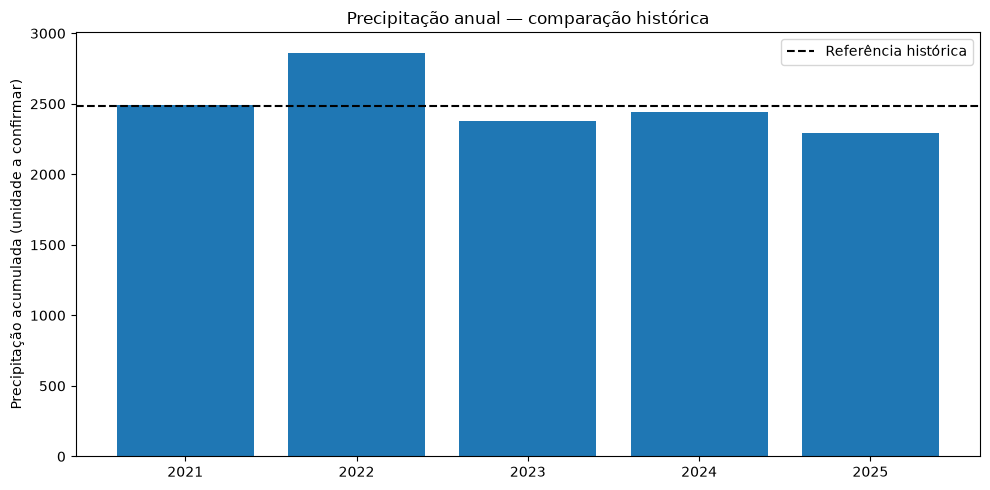

In [4]:
# Usar apenas anos completos
resumo = (
    periodo.groupby("ano")
    .agg(
        acumulado=("precipitacao_mensal", "sum"),
        meses_validos=("precipitacao_mensal", "count")
    )
    .reset_index()
)

resumo = resumo[resumo["meses_validos"] == 12].copy()

referencia_anual = referencia["referencia_30_anos"].sum()

resumo["referencia_anual"] = referencia_anual

resumo["diferenca_percentual"] = (
    (resumo["acumulado"] - referencia_anual)
    / referencia_anual * 100
).round(2)

display(resumo)

plt.figure(figsize=(10, 5))

plt.bar(
    resumo["ano"].astype(str),
    resumo["acumulado"]
)

plt.axhline(
    referencia_anual,
    color="black",
    linestyle="--",
    label="Referência histórica"
)

plt.title("Precipitação anual — comparação histórica")
plt.ylabel("Precipitação acumulada (unidade a confirmar)")
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
DESTINO = BASE

maiores_desvios.to_csv(
    DESTINO / "precipitacao_maiores_desvios.csv",
    index=False,
    encoding="utf-8-sig"
)

resumo.to_csv(
    DESTINO / "precipitacao_comparacao_anual.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Insights exportados para:", DESTINO)

Insights exportados para: C:\Users\Lenovo\Desktop\porto-santos\data\processed\precipitacao_historica
